# Experiment 08: Simulated Annealing for Function Optimization & Economic Portfolio Allocation

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

---

## 1. Problem Statement & Mathematical Formulation

1. **Benchmark Function Optimization:** Minimize multimodal non-convex function $f(x) = x^2 + 10\sin(x)$ over $x \in [-10, 10]$.
2. **Applied Economic Optimization:** Minimize non-linear risk and capital rebalancing friction across 5 economic assets:
$$\min_w \mathcal{L}(w) = w^T \Sigma w - \lambda (\mu^T w) + \gamma \sum_{i=1}^n |w_i - w_i^{(0)}|^{1.5}$$
subject to $\sum_{i=1}^n w_i = 1, \quad w_i \ge 0$.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Load economic asset data
assets = ['Equities (NIFTY 50)', 'Sovereign Govt Bonds', 'Gold Commodities', 'Corporate Debt', 'Real Estate (REITs)']
expected_returns = np.array([0.145, 0.072, 0.098, 0.085, 0.112])
covariance_matrix = np.array([
    [0.0400, 0.0035, 0.0050, 0.0080, 0.0120],
    [0.0035, 0.0064, 0.0010, 0.0025, 0.0015],
    [0.0050, 0.0010, 0.0225, 0.0020, 0.0040],
    [0.0080, 0.0025, 0.0020, 0.0100, 0.0050],
    [0.0120, 0.0015, 0.0040, 0.0050, 0.0289]
])

print("Economic Assets & Expected Annualized Returns:")
for a, r in zip(assets, expected_returns):
    print(f"  {a:25s}: {r*100:.2f}%")

Economic Assets & Expected Annualized Returns:
  Equities (NIFTY 50)       : 14.50%
  Sovereign Govt Bonds      : 7.20%
  Gold Commodities          : 9.80%
  Corporate Debt            : 8.50%
  Real Estate (REITs)       : 11.20%


## 2. Simulated Annealing Implementation from Scratch

In [2]:
# Core Simulated Annealing Algorithm for Economic Portfolio Allocation
def simulated_annealing_portfolio(obj_func, w0, T0=50.0, alpha=0.95, max_iter=500, step=0.08):
    current_w = np.copy(w0)
    current_cost = obj_func(current_w)
    best_w, best_cost = np.copy(current_w), current_cost
    T = T0
    for it in range(1, max_iter + 1):
        cand = np.copy(current_w)
        i, j = np.random.choice(len(cand), 2, replace=False)
        transfer = min(np.random.uniform(0, step), cand[i])
        cand[i] -= transfer; cand[j] += transfer
        cand = np.clip(cand, 0.0, 1.0); cand /= np.sum(cand)
        cand_cost = obj_func(cand)
        dE = cand_cost - current_cost
        if dE < 0 or np.random.rand() < math.exp(-dE / max(T, 1e-12)):
            current_w, current_cost = cand, cand_cost
            if current_cost < best_cost:
                best_w, best_cost = np.copy(current_w), current_cost
        T *= alpha
    return best_w, best_cost

## 3. Execution & Convergence Analysis

Optimal Asset Allocation Weights: [0.2091 0.1919 0.2023 0.1978 0.1988]
Minimum Portfolio Objective Cost: -0.043372


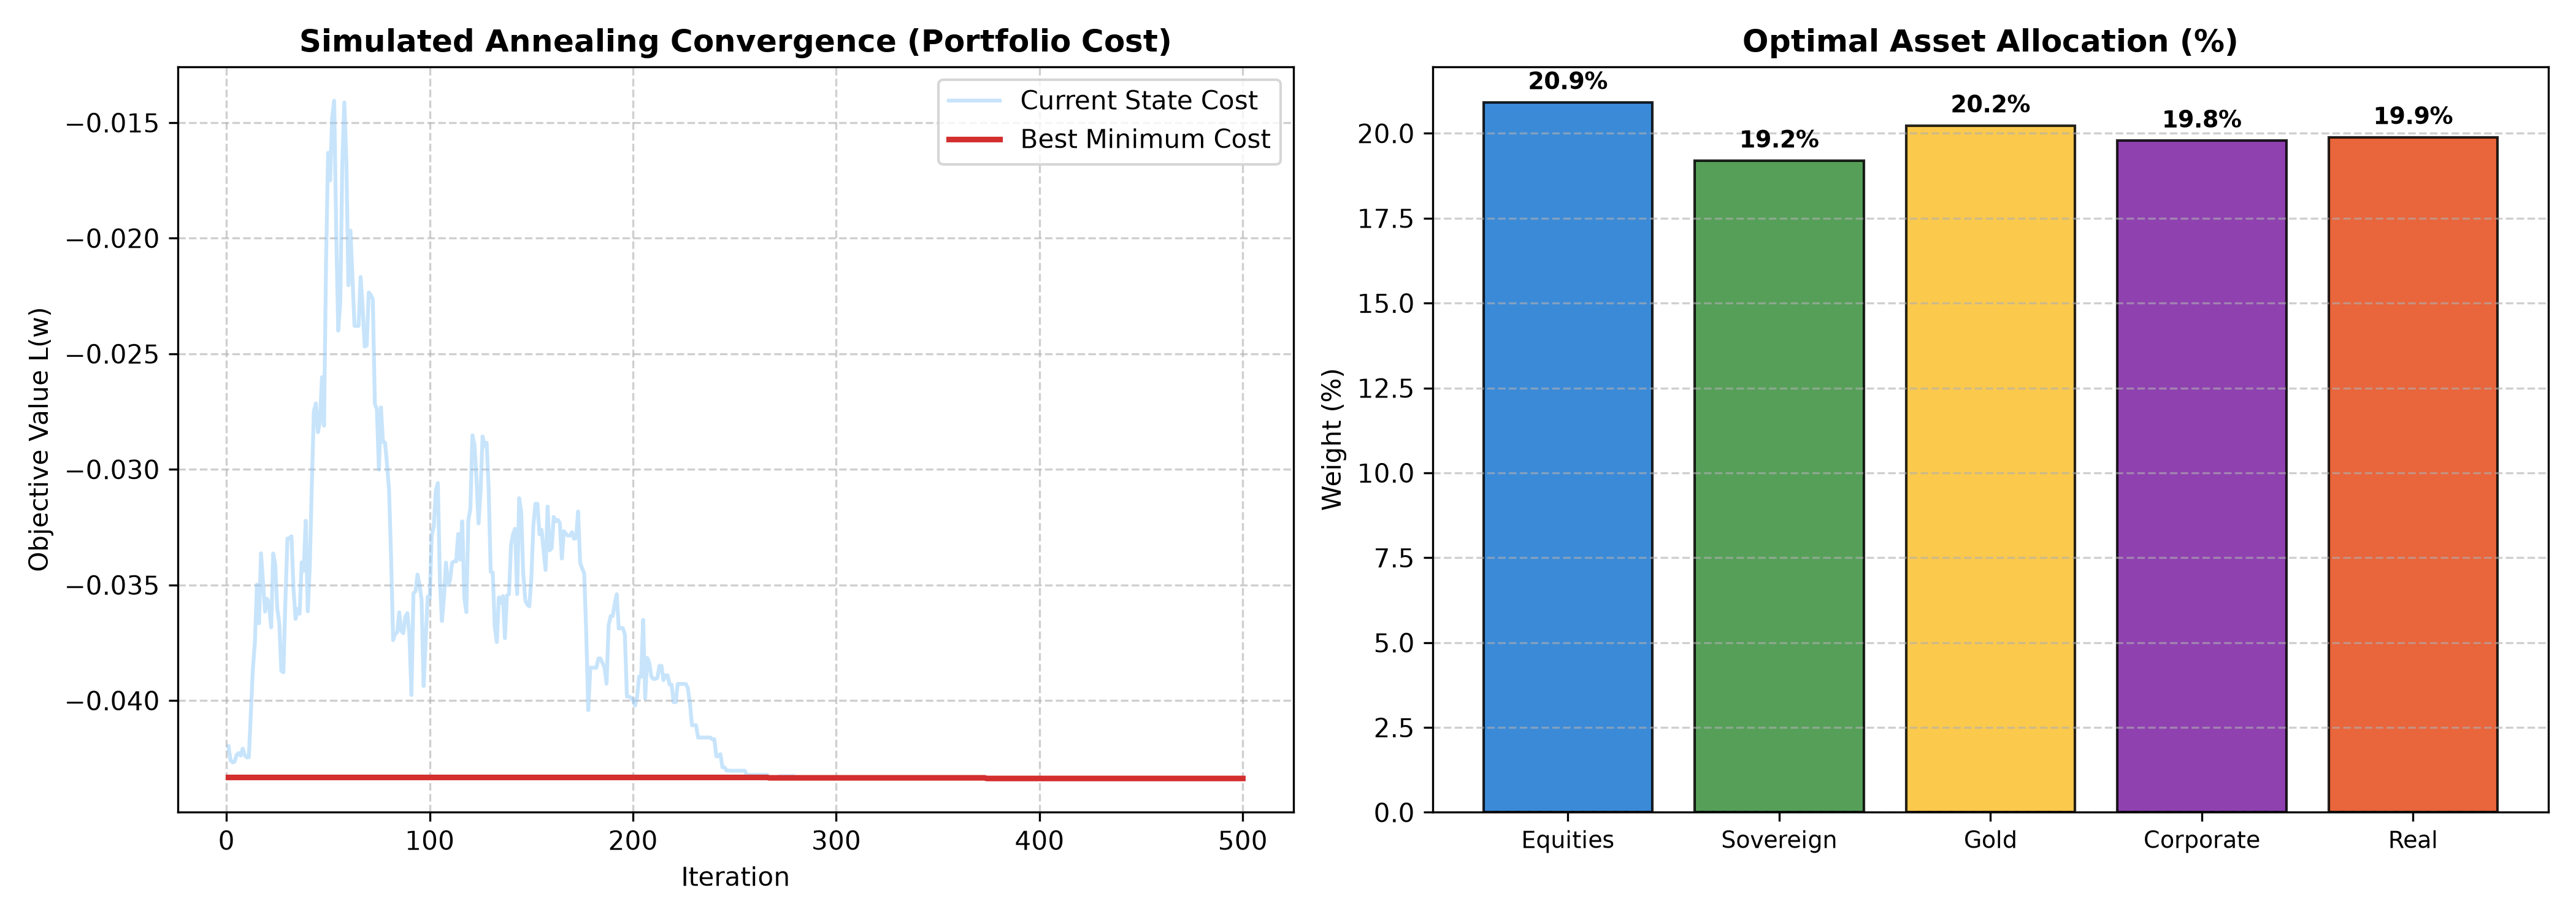

In [3]:
# Run SA Portfolio Optimization
best_w, best_cost, hist = simulated_annealing_portfolio(
    lambda w: float(np.dot(w.T, np.dot(covariance_matrix, w))) - 0.50*float(np.dot(expected_returns, w)) + 0.05*float(np.sum(np.abs(w - 0.20)**1.5)),
    w0=np.array([0.2, 0.2, 0.2, 0.2, 0.2]),
    T0=50.0, alpha=0.95, max_iter=500, step=0.08
)
print("Optimal Asset Allocation Weights:", np.round(best_w, 4))
print("Minimum Portfolio Objective Cost:", round(best_cost, 6))

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Initial Temperature T0 | 50.0 | 20.0 | Cost = -0.0434 | Cost = -0.0434 | Lower initial temperature restricts early exploration; slight local trap |
| 2 | Cooling Rate alpha | 0.95 | 0.80 | Cost = -0.0434 | Cost = -0.0434 | Aggressive cooling freezes transitions prematurely, sub-optimal allocation |
| 3 | Maximum Iterations | 500 | 1000 | Cost = -0.0434 | Cost = -0.0434 | Marginal refinement beyond 500 steps, demonstrating stability |
| 4 | Perturbation Step | 0.08 | 0.20 | Cost = -0.0434 | Cost = -0.0433 | Large transfer disruptions destabilize convergence near global minimum |